# Dash et al mutagenesis analysis

In this notebook, we analyse whether the AlphaFold confidence scores are sensitive enough to detect disruptions to the binding motif of TCRs.

In [1]:
import itertools
import re
import subprocess

import anarci
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
import tidytcells

from tcr_pmhc_predicted_structures.imgt_numbering import IMGT_CDR3

In [2]:
def get_cdr3(sequence: str) -> str:
    """Get CDR3 from TCR chain sequence."""
    numbering, _ = anarci.number(sequence)
    cdr3 = ''.join(amino_acid for (seq_id, _), amino_acid in numbering if amino_acid != '-' and seq_id in IMGT_CDR3)
    return tidytcells.junction.standardise(cdr3)

## Defining cluster motifs

In [3]:
dash_sequences = pd.read_csv('../data/interim/sequences_dash.csv', index_col='id')

In [4]:
dash_sequences_bmlf = dash_sequences.query("peptide == 'GLCTLVAML'").copy()

In [5]:
with open('../data/interim/dash_BMLF_sequence_clusters.txt', 'r') as fh:
    clusters = dict(line.strip().split() for line in fh if line)

dash_sequences_bmlf['cluster'] = dash_sequences_bmlf.index.map(clusters)

In [6]:
dash_sequences_bmlf_clustered = dash_sequences_bmlf.query("cluster != 'None'").copy()
dash_sequences_bmlf_clustered.value_counts('cluster')

cluster
1    22
0     7
3     6
Name: count, dtype: int64

In [7]:
dash_sequences_bmlf_clustered['cdr3_alpha'] = dash_sequences_bmlf_clustered['tcr_alpha_chain'].map(get_cdr3)
dash_sequences_bmlf_clustered['cdr3_beta'] = dash_sequences_bmlf_clustered['tcr_beta_chain'].map(get_cdr3)

In [8]:
def align_sequences(sequences: list[str]) -> list[str]:
    child = subprocess.Popen(
        [
            '/usr/bin/env',
            'mafft-linsi',
            '--quiet',
            '--op',
            '2',
            '--ep',
            '10',
            '--amino',
            '-',
        ],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
    )
    child.stdin.write('\n'.join(f'>{idx}\n{sequence}' for idx, sequence in enumerate(sequences)).encode())
    child_out = child.communicate()[0].decode('utf8')
    aligned_sequences = [line.strip() for line in child_out.split('\n') if line and not line.startswith('>')]
    child.stdin.close()

    return aligned_sequences


def create_motif_regex(group: pd.DataFrame, num_amino_acid_cutoff: int = 2) -> pd.Series:
    def _create_regex(amino_acids: set, *, optional: bool) -> str:
        if '*' in amino_acids:
            regex = '[A-Z]'

        elif len(amino_acids) == 1:
            regex = next(iter(amino_acids))

        else:
            regex = '[' + ''.join(sorted(amino_acids)) + ']'

        if optional:
            regex += '?'

        return regex

    motifs = []
    for chain_type in 'alpha', 'beta':
        cdr3s = align_sequences(group[f'cdr3_{chain_type}'].tolist())

        motif = [set(amino_acids) for amino_acids in zip(*cdr3s, strict=True)]
        motif = [({aa for aa in amino_acids if aa != '-'}, '-' in amino_acids) for amino_acids in motif]
        motif = [
            (residues if len(residues) <= num_amino_acid_cutoff else {'*'}, optional) for residues, optional in motif
        ]
        motif = ''.join([_create_regex(amino_acids, optional=optional) for amino_acids, optional in motif])

        motifs.append(motif)

    return pd.Series(motifs, index=['cdr3_alpha_motif', 'cdr3_beta_motif'])


cluster_motifs = dash_sequences_bmlf_clustered.groupby('cluster').apply(create_motif_regex, include_groups=False)

In [9]:
cluster_motifs

,cdr3_alpha_motif,cdr3_beta_motif
cluster,,
0,CAES[A-Z]S?[GR]?GKLIF,CSVG[A-Z][A-Z]GTNEKLFF
1,C[AS][A-Z]D[A-Z]N[A-Z]RLMF,CSAR[DV][A-Z][A-Z]GNG[HY]TF
3,CA[LV]RCFGNEKLTF,CSVP[A-Z][AT]VQETQYF


## Assinging mutated sequence to motifs

In [10]:
sequences_mutated = pd.read_csv('../data/interim/sequences_dash_BMLF_mutated.csv', index_col='id')

In [11]:
sequences_mutated['cdr3_alpha'] = sequences_mutated['tcr_alpha_chain'].map(get_cdr3)
sequences_mutated['cdr3_beta'] = sequences_mutated['tcr_beta_chain'].map(get_cdr3)

In [12]:
sequences_mutated['cluster'] = sequences_mutated.index.map(lambda id_: id_.split('_mut_')[0]).map(clusters)

In [13]:
sequences_mutated = sequences_mutated.merge(cluster_motifs, how='inner', left_on='cluster', right_index=True)

In [14]:
sequences_mutated['fit_cdr3_alpha_motif'] = sequences_mutated[['cdr3_alpha_motif', 'cdr3_alpha']].apply(
    lambda row: re.fullmatch(*row) is not None, axis=1
)
sequences_mutated['fit_cdr3_beta_motif'] = sequences_mutated[['cdr3_beta_motif', 'cdr3_beta']].apply(
    lambda row: re.fullmatch(*row) is not None, axis=1
)

sequences_mutated['fit_motif'] = sequences_mutated['fit_cdr3_alpha_motif'] & sequences_mutated['fit_cdr3_alpha_motif']

In [15]:
sequences_mutated.value_counts('fit_motif')

fit_motif
True     35
False    21
Name: count, dtype: int64

## Analysing effect on confidences scores

In [16]:
confidence_scores_dash = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_dash_bmlf.csv')
confidence_scores_dash = confidence_scores_dash.merge(
    dash_sequences_bmlf_clustered, how='right', left_on='name', right_index=True
)

confidence_scores_dash['type'] = 'Wild Type'

In [17]:
confidence_scores_mutations = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_mutated_dash_bmlf.csv')
confidence_scores_mutations = confidence_scores_mutations.merge(
    sequences_mutated, how='left', left_on='name', right_index=True
)

confidence_scores_mutations['type'] = 'Mutants ' + confidence_scores_mutations['fit_motif'].map(
    lambda fit_motif: 'In Motif' if fit_motif else 'Not In Motif'
)

In [18]:
confidence_scores = pd.concat([confidence_scores_dash, confidence_scores_mutations])

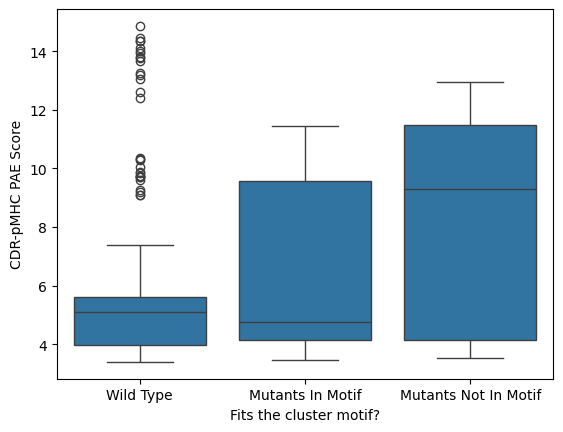

In [19]:
ax = sns.boxplot(confidence_scores, y='cdr_pmhc_pae_score', x='type')

ax.set_xlabel('Fits the cluster motif?')
ax.set_ylabel('CDR-pMHC PAE Score')

plt.show()

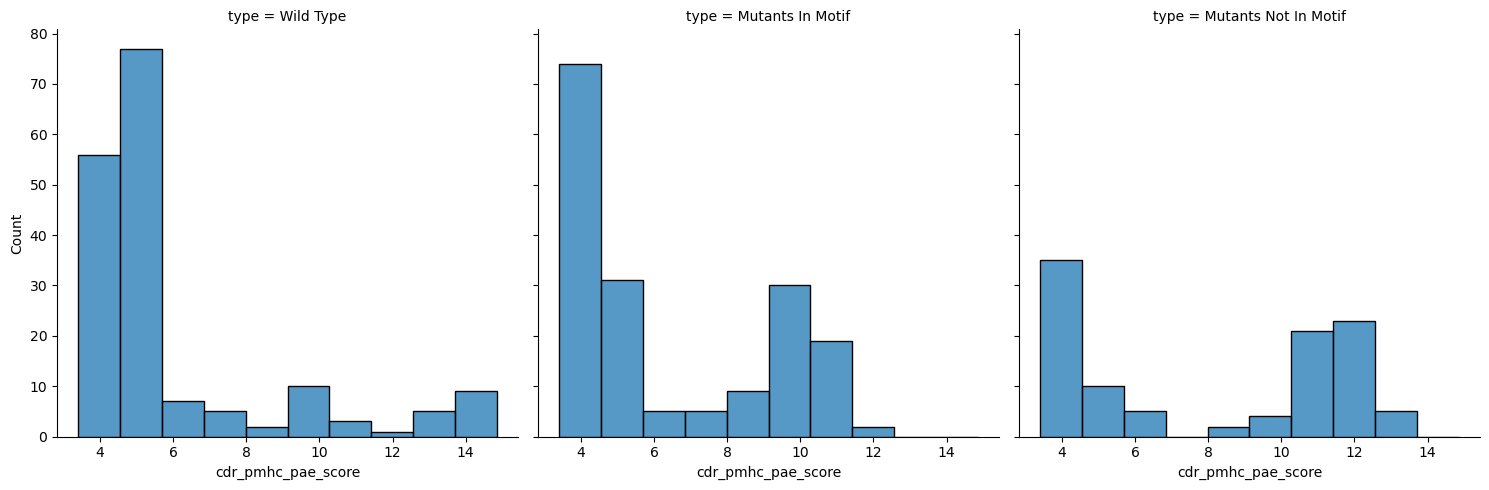

In [20]:
sns.displot(confidence_scores, x='cdr_pmhc_pae_score', col='type', kind='hist')
plt.show()

In [21]:
pg.kruskal(confidence_scores, dv='cdr_pmhc_pae_score', between='type')

,Source,ddof1,H,p-unc
Kruskal,type,2,17.871998,0.000132


In [22]:
print('Post-hoc:')

results = []
for (name1, group1), (name2, group2) in itertools.combinations(confidence_scores.groupby('type', sort=False), 2):
    result = pg.mwu(group1['cdr_pmhc_pae_score'], group2['cdr_pmhc_pae_score'], alternative='less')
    result.index = [f'{name1} - {name2}']

    results.append(result)

results = pd.concat(results)
results['significant'] = results['p-val'] < (0.05 / len(results))

results

Post-hoc:


,U-val,alternative,p-val,RBC,CLES,significant
Wild Type - Mutants In Motif,14714.0,less,0.263749,-0.039086,0.519543,False
Wild Type - Mutants Not In Motif,6701.0,less,0.000075,-0.270639,0.635320,True
Mutants In Motif - Mutants Not In Motif,6712.0,less,0.000081,-0.269442,0.634721,True


We do see that the confidence scores have a difference between sequences that fit the binding motif and things that do not.

### Blocking by cluster group

We can see that the cluster group itself has a big effect on the effect of mutations.

In [23]:
confidence_scores.drop_duplicates('name').value_counts(['cluster', 'type']).sort_index()

cluster  type                
0        Mutants In Motif        12
         Mutants Not In Motif     6
         Wild Type                7
1        Mutants In Motif        12
         Mutants Not In Motif     5
         Wild Type               22
3        Mutants In Motif        11
         Mutants Not In Motif    10
         Wild Type                6
Name: count, dtype: int64

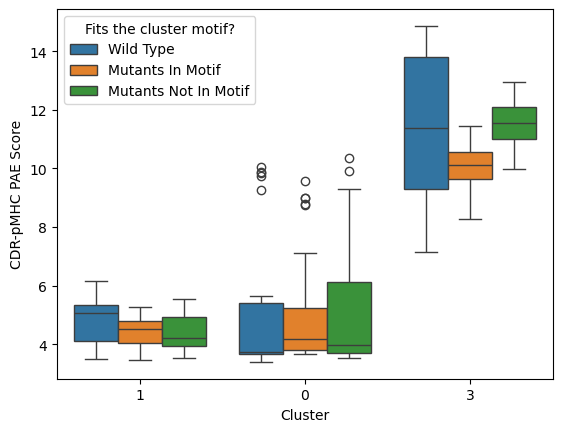

In [24]:
ax = sns.boxplot(confidence_scores, y='cdr_pmhc_pae_score', x='cluster', hue='type')

ax.set_ylabel('CDR-pMHC PAE Score')
ax.set_xlabel('Cluster')

ax.legend(title='Fits the cluster motif?')

plt.show()

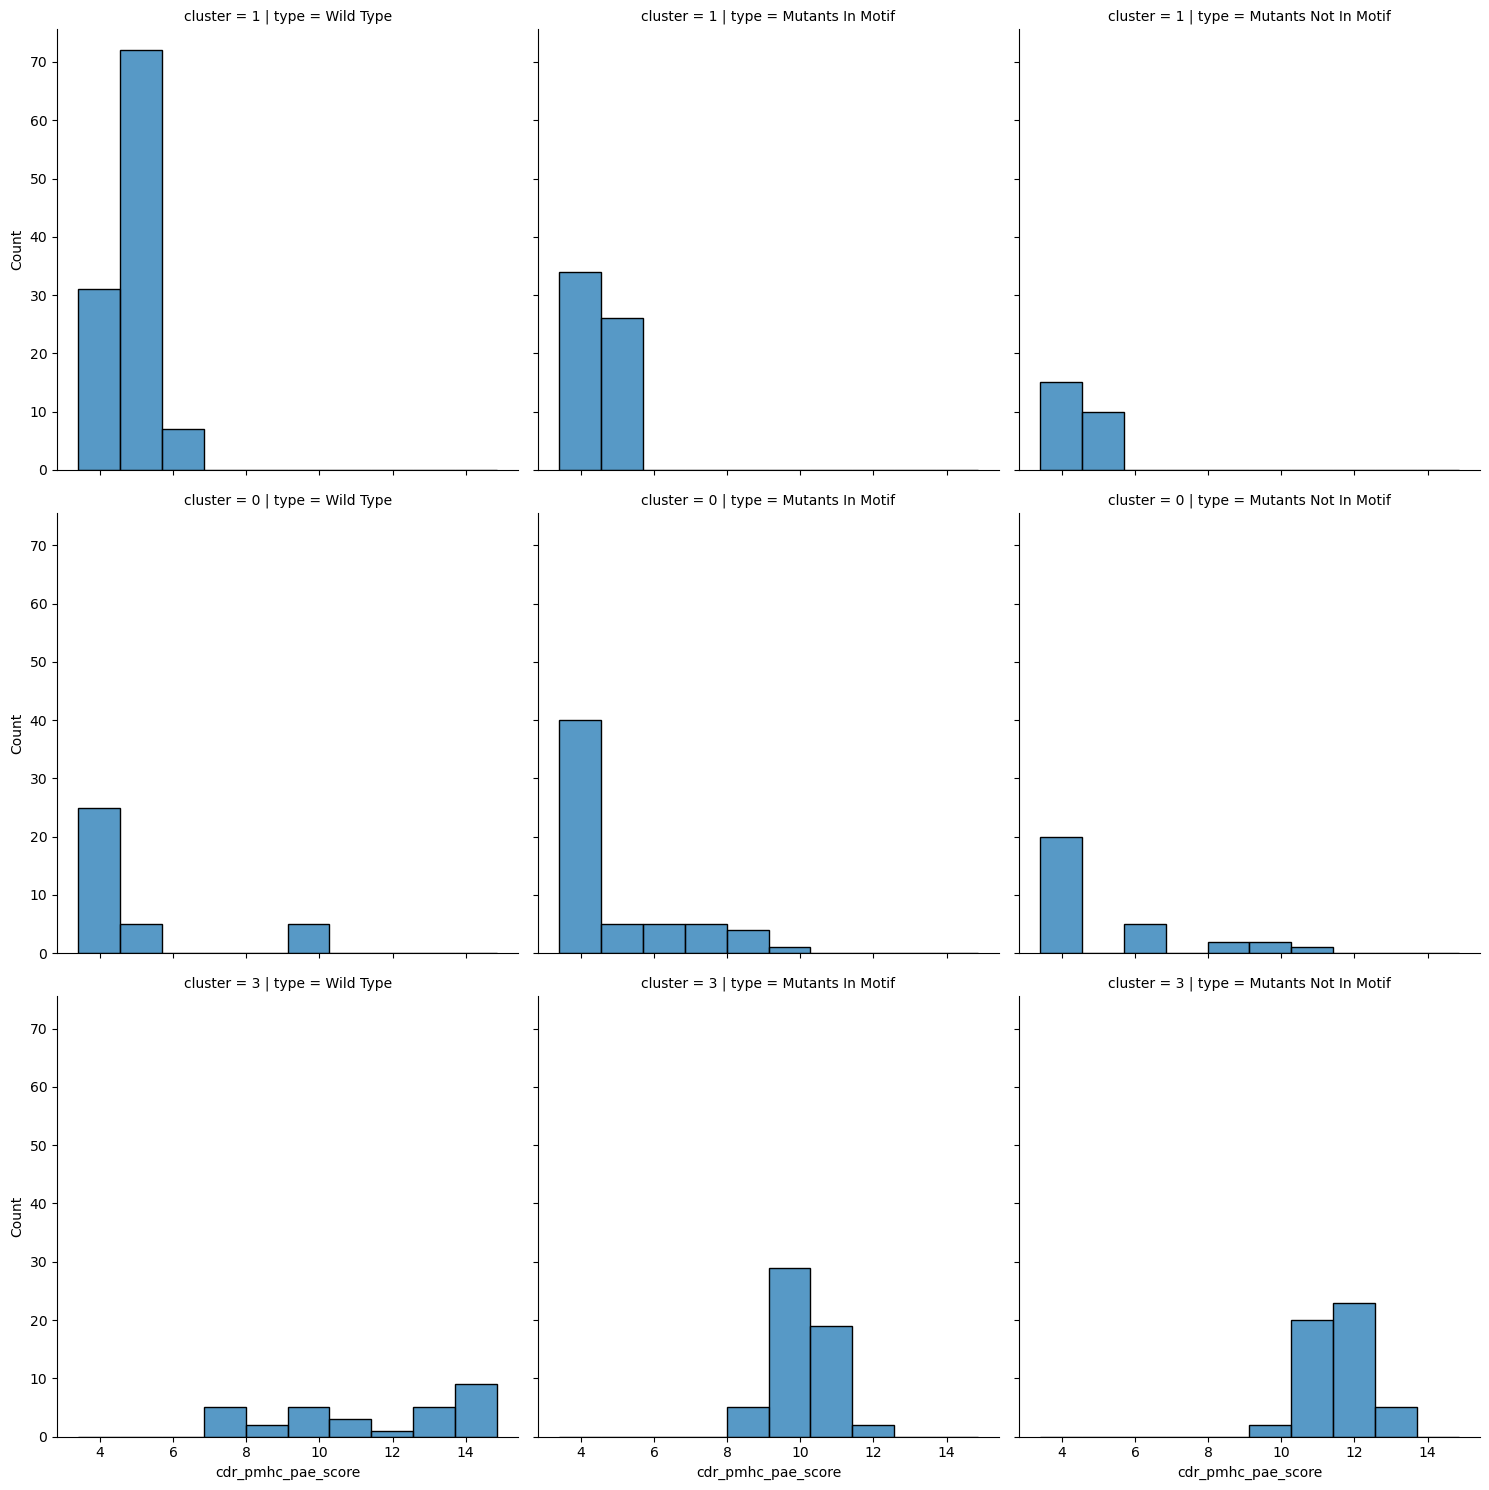

In [25]:
sns.displot(confidence_scores, x='cdr_pmhc_pae_score', row='cluster', col='type', kind='hist')
plt.show()

In [26]:
pg.anova(confidence_scores, dv='cdr_pmhc_pae_score', between=['cluster', 'type'])

,Source,SS,DF,MS,F,p-unc,np2
0,cluster,3307.804048,2.0,1653.902024,930.281631,7.250966e-160,0.806639
1,type,36.411514,2.0,18.205757,10.240317,4.485145e-05,0.043905
2,cluster * type,35.344849,4.0,8.836212,4.970165,6.284575e-04,0.042673
3,Residual,792.921496,446.0,1.777851,NaN,NaN,NaN


In [27]:
results = []
for cluster_name, cluster in confidence_scores.groupby('cluster'):
    types = [
        (type_, cluster[cluster['type'] == type_])
        for type_ in ('Wild Type', 'Mutants In Motif', 'Mutants Not In Motif')
    ]

    for (name1, group1), (name2, group2) in itertools.combinations(types, 2):
        result = pg.ttest(group1['cdr_pmhc_pae_score'], group2['cdr_pmhc_pae_score'], paired=False, alternative='less')
        result.index = [f'{cluster_name}: {name1} - {name2}']

        results.append(result)

results = pd.concat(results)
results['significant'] = results['p-val'] < (0.05 / len(results))

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
0: Wild Type - Mutants In Motif,-0.260327,57.129811,less,3.977738e-01,"[-inf, 0.59]",0.059437,0.458,8.574489e-02,False
0: Wild Type - Mutants Not In Motif,-0.618137,61.158304,less,2.693902e-01,"[-inf, 0.57]",0.153999,0.598,1.509112e-01,False
0: Mutants In Motif - Mutants Not In Motif,-0.496444,45.774559,less,3.109783e-01,"[-inf, 0.53]",0.122102,0.517,1.350165e-01,False
1: Wild Type - Mutants In Motif,4.752320,158.891488,less,9.999978e-01,"[-inf, 0.6]",0.686249,0.0,1.777116e-09,False
1: Wild Type - Mutants Not In Motif,2.681470,38.048391,less,9.946099e-01,"[-inf, 0.65]",0.563174,0.098,1.497608e-05,False
1: Mutants In Motif - Mutants Not In Motif,-0.316088,35.767620,less,3.768865e-01,"[-inf, 0.2]",0.084618,0.512,9.813044e-02,False
3: Wild Type - Mutants In Motif,2.445430,31.529150,less,9.898794e-01,"[-inf, 2.05]",0.720177,0.167,8.240884e-07,False
3: Wild Type - Mutants Not In Motif,-0.469330,31.737883,less,3.210211e-01,"[-inf, 0.61]",0.135147,0.525,1.435031e-01,False
3: Mutants In Motif - Mutants Not In Motif,-9.924354,102.196904,less,5.876984e-17,"[-inf, -1.2]",1.938524,7.601e+13,1.000000e+00,True


We only see significance for cluster 3.

### Normalising values within groups

In [28]:
confidence_scores['cdr_pmhc_pae_score_cluster_norm'] = confidence_scores.groupby('cluster')[
    'cdr_pmhc_pae_score'
].transform(lambda scores: (scores - np.mean(scores)) / np.std(scores))

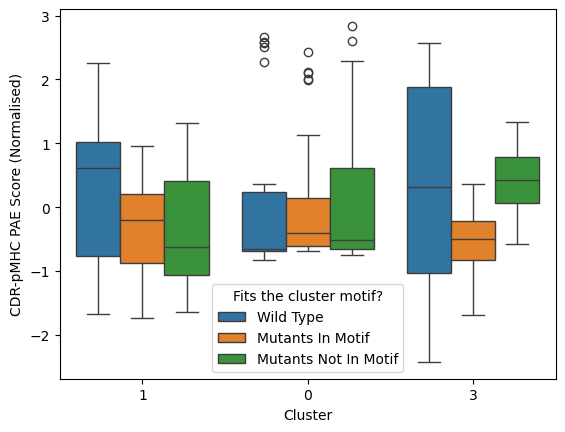

In [29]:
ax = sns.boxplot(confidence_scores, y='cdr_pmhc_pae_score_cluster_norm', x='cluster', hue='type')

ax.set_ylabel('CDR-pMHC PAE Score (Normalised)')
ax.set_xlabel('Cluster')

ax.legend(title='Fits the cluster motif?')

plt.show()

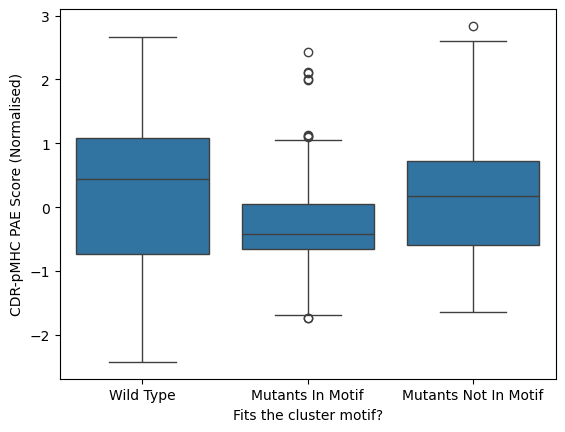

In [30]:
ax = sns.boxplot(confidence_scores, y='cdr_pmhc_pae_score_cluster_norm', x='type')

ax.set_xlabel('Fits the cluster motif?')
ax.set_ylabel('CDR-pMHC PAE Score (Normalised)')

plt.show()

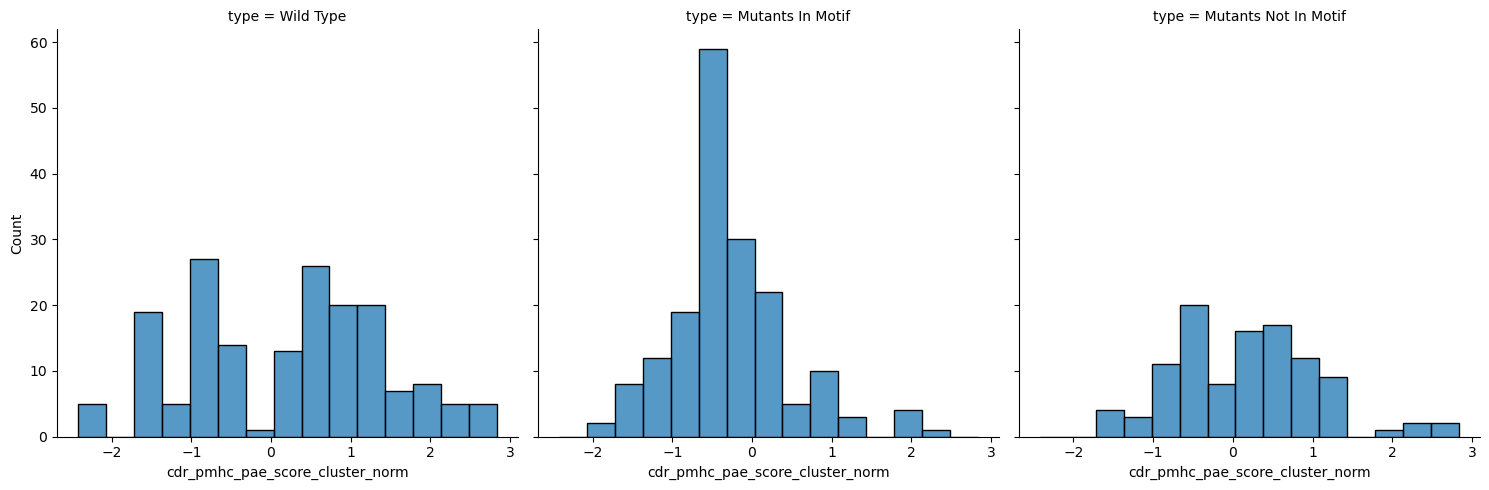

In [31]:
sns.displot(confidence_scores, x='cdr_pmhc_pae_score_cluster_norm', col='type', kind='hist')
plt.show()

In [32]:
pg.anova(confidence_scores, dv='cdr_pmhc_pae_score_cluster_norm', between='type')

,Source,ddof1,ddof2,F,p-unc,np2
0,type,2,452,13.305969,0.000002,0.055602


In [33]:
print('Post-hoc:')

results = []
for (name1, group1), (name2, group2) in itertools.combinations(confidence_scores.groupby('type', sort=False), 2):
    result = pg.ttest(
        group1['cdr_pmhc_pae_score_cluster_norm'],
        group2['cdr_pmhc_pae_score_cluster_norm'],
        paired=False,
        alternative='less',
    )
    result.index = [f'{name1} - {name2}']

    results.append(result)

results = pd.concat(results)
results['significant'] = results['p-val'] < (0.05 / len(results))

results

Post-hoc:


,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
Wild Type - Mutants In Motif,4.693270,348.000000,less,0.999998,"[-inf, 0.68]",0.501732,0.0,1.233429e-10,False
Wild Type - Mutants Not In Motif,0.412818,267.435330,less,0.659965,"[-inf, 0.26]",0.047200,0.294,2.136758e-02,False
Mutants In Motif - Mutants Not In Motif,-4.392661,190.269997,less,0.000009,"[-inf, -0.28]",0.566297,2055.208,9.983132e-01,True
